In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import joblib

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

In [2]:
df = pd.read_csv(
    "../data/credit_card_default_clean.csv"
)

target = "default.payment.next.month"

X = df.drop(columns=[target])
y = df[target]

print("Dataset shape:", df.shape)

Dataset shape: (29965, 24)


In [4]:
categorical_features = [
    "SEX", "EDUCATION", "MARRIAGE",
    "PAY_0", "PAY_2", "PAY_3",
    "PAY_4", "PAY_5", "PAY_6"
]

for col in categorical_features:
    for col in categorical_features:
        if col in X.columns:
            X[col] = X[col].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


In [5]:
model = joblib.load(
    "../artifacts/loan_default_pipeline.joblib"
)

print("Model loaded successfully!")

Model loaded successfully!


In [6]:
y_pred = model.predict(X_test)

y_prob = model.predict_proba(X_test)[:, 1]

[[3279 1388]
 [ 491  835]]


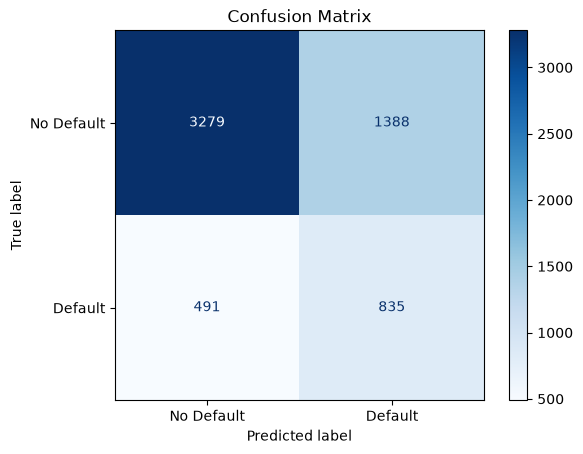

In [7]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Default", "Default"]
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

In [8]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Default", "Default"]
    )
)

              precision    recall  f1-score   support

  No Default       0.87      0.70      0.78      4667
     Default       0.38      0.63      0.47      1326

    accuracy                           0.69      5993
   macro avg       0.62      0.67      0.62      5993
weighted avg       0.76      0.69      0.71      5993



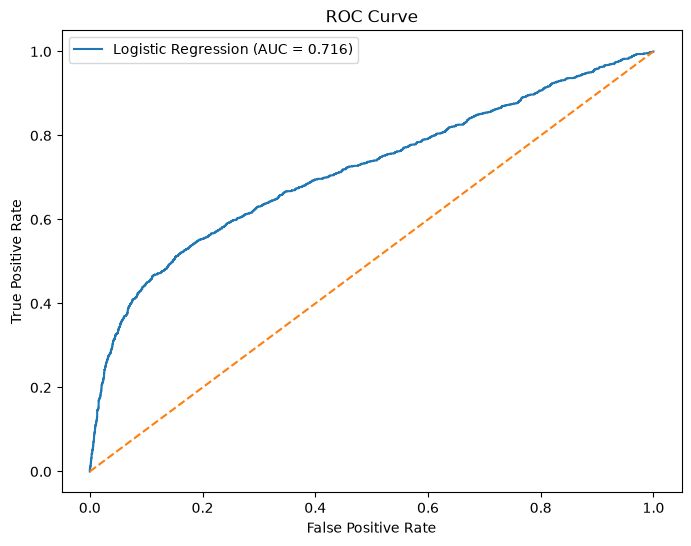

ROC-AUC: 0.7161577986834167


In [9]:
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob
)

auc_score = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {auc_score:.3f})"
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()
plt.show()

print("ROC-AUC:", auc_score)

In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

random_forest = Pipeline([
    ("preprocessor", model.named_steps["preprocessor"]),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

random_forest.fit(X_train, y_train)

rf_pred = random_forest.predict(X_test)
rf_prob = random_forest.predict_proba(X_test)[:, 1]

In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, rf_pred),
        "Precision": precision_score(y_test, rf_pred, zero_division=0),
        "Recall": recall_score(y_test, rf_pred, zero_division=0),
        "F1": f1_score(y_test, rf_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, rf_prob)
    }
])

results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.686468,0.375619,0.629713,0.470555,0.716158
1,Random Forest,0.778909,0.500335,0.563348,0.529975,0.772022


In [13]:
results.to_csv(
    "../data/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [14]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    model,
    X_test,
    y_test,
    n_repeats=5,
    random_state=42,
    scoring="roc_auc",
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(10)

,Feature,Importance,Std
5,X6,0.106188,0.007461
11,X12,0.028672,0.004820
12,X13,0.011753,0.002512
0,X1,0.006719,0.000980
17,X18,0.005863,0.001324
18,X19,0.003260,0.001212
6,X7,0.003249,0.000309
3,X4,0.002832,0.000822
4,X5,0.002555,0.001252
7,X8,0.002239,0.000649


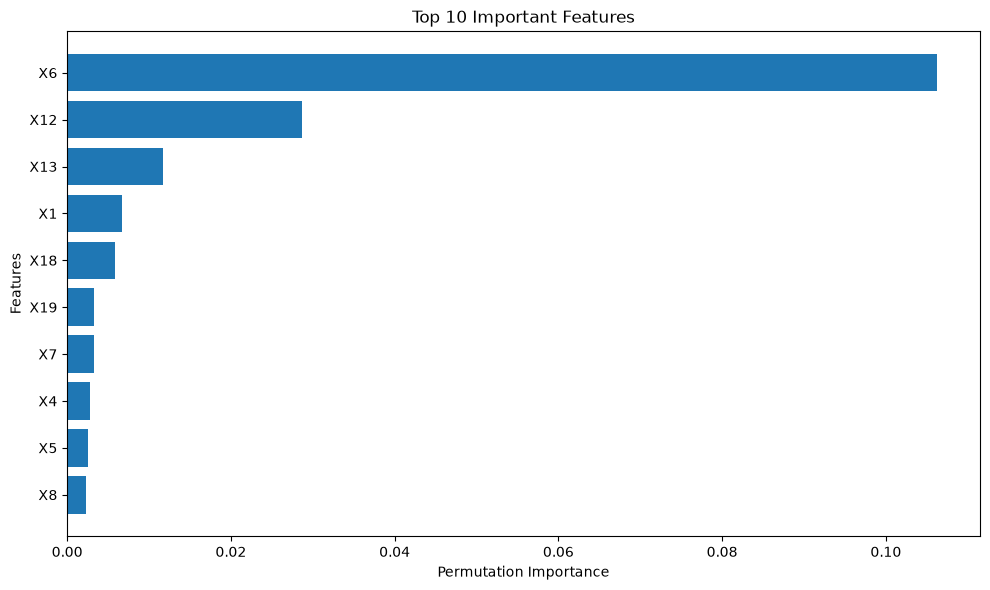

In [15]:
top_features = feature_importance.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Permutation Importance")
plt.ylabel("Features")
plt.title("Top 10 Important Features")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [17]:
# probability for the first row in the test set
probability = model.predict_proba(X_test.iloc[[0]])[0, 1]

prediction = int(probability >= 0.5)

print(f"Probability: {probability:.4f}")
print(f"Prediction: {prediction}")

Probability: 0.5089
Prediction: 1


In [18]:
thresholds = [0.30, 0.40, 0.50]

for threshold in thresholds:

    predictions = (y_prob >= threshold).astype(int)

    print("\nThreshold:", threshold)

    print(
        classification_report(
            y_test,
            predictions,
            zero_division=0
        )
    )


Threshold: 0.3
              precision    recall  f1-score   support

           0       0.88      0.23      0.36      4667
           1       0.25      0.89      0.39      1326

    accuracy                           0.37      5993
   macro avg       0.56      0.56      0.37      5993
weighted avg       0.74      0.37      0.37      5993


Threshold: 0.4
              precision    recall  f1-score   support

           0       0.87      0.43      0.57      4667
           1       0.28      0.78      0.41      1326

    accuracy                           0.50      5993
   macro avg       0.57      0.60      0.49      5993
weighted avg       0.74      0.50      0.54      5993


Threshold: 0.5
              precision    recall  f1-score   support

           0       0.87      0.70      0.78      4667
           1       0.38      0.63      0.47      1326

    accuracy                           0.69      5993
   macro avg       0.62      0.67      0.62      5993
weighted avg       0.76   

In [19]:
feature_importance.to_csv(
    "../data/feature_importance.csv",
    index=False
)

print("Feature importance saved!")

Feature importance saved!


   Feature  Importance
5       X6    0.092909
11     X12    0.051415
12     X13    0.013931
6       X7    0.005687
17     X18    0.004326
15     X16    0.004090
1       X2    0.003962
7       X8    0.003410
16     X17    0.003144
0       X1    0.002677
8       X9    0.002377
3       X4    0.002224
4       X5    0.002097
9      X10    0.001541
19     X20    0.001179
18     X19    0.001128
13     X14    0.000816
10     X11    0.000724
14     X15    0.000598
21     X22    0.000425
22     X23    0.000347
20     X21    0.000150
2       X3   -0.001166


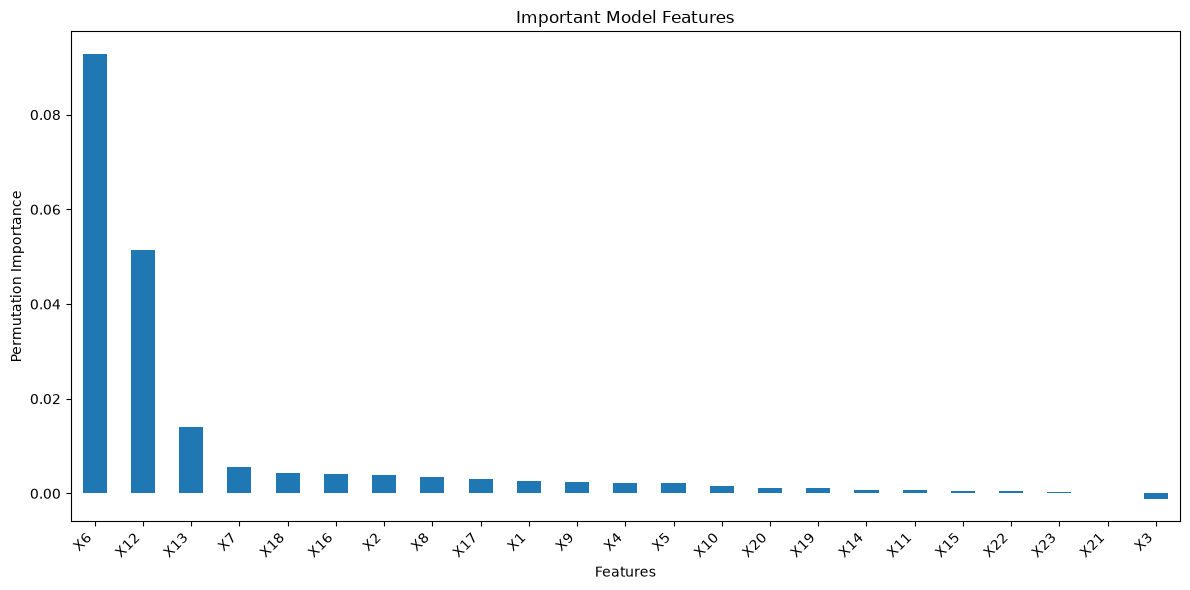

In [25]:
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

importance = permutation_importance(
    model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="f1"
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df)

importance_df.plot(
    x="Feature",
    y="Importance",
    kind="bar",
    figsize=(12, 6),
    legend=False
)

plt.title("Important Model Features")
plt.xlabel("Features")
plt.ylabel("Permutation Importance")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()